# Lazy loading of the hist IRF

`IRFRelativeHistUnpolarized.from_h5` no longer reads the whole response (9.6 GB of
contents for `hist_simple`). Each `NuLambda` pixel is read and normalized the first time
an evaluation needs it. A point source only visits a few pixels of the spacecraft frame
during an observation, so only those take memory. `preload=True` reads everything up front.

This notebook loads the real `hist_simple` response both ways, evaluates the same events
from a source drifting across the spacecraft frame, and compares results, time and memory.

In [1]:
import resource
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import astropy.units as u
from mhealpy import HealpixMap

from cosipy.data_io.EmCDSUnbinnedData import EmCDSEventDataInSCFrameFromArrays
from cosipy.event_selection.energy_selection import EnergySelector
from cosipy.response.photon_types import PhotonListWithDirectionAndEnergyInSCFrame
from cosipy.response.relative_irf_hist import IRFRelativeHistUnpolarized

# threeML (imported by cosipy) sets a non-interactive backend without a display
%matplotlib inline


WARNING TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html



In [2]:
data_path = Path('/home/user/irftest')
irf_file = data_path / 'ResponseContinuum.area.relative.nonsparse_smoothing1p0.h5'
selection = EnergySelector([200., 5000.] * u.keV)


def peak_memory_GB():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6

Events from a source that drifts 20 deg in the spacecraft frame (about 3 h of zenith
pointing), with energies from 200 keV to 5 MeV. The event coordinates are random: only the
evaluation matters here, not the physics.

In [3]:
rng = np.random.default_rng(0)
n = 200_000
lon = np.deg2rad(30 + 20 * rng.random(n))
lat = np.deg2rad(np.full(n, 50.))
energy = np.exp(rng.uniform(np.log(200), np.log(5000), n))

photons = PhotonListWithDirectionAndEnergyInSCFrame(lon, lat, energy)
events = EmCDSEventDataInSCFrameFromArrays(energy * rng.uniform(0.5, 1.05, n), rng.uniform(-np.pi, np.pi, n),
                                           np.arcsin(rng.uniform(-1, 1, n)), rng.uniform(0, np.pi, n))

## Lazy (the default)

In [4]:
t0 = time.time()
lazy = IRFRelativeHistUnpolarized.from_h5(irf_file, selections=selection)
print(f'construction: {time.time() - t0:.1f} s, peak memory {peak_memory_GB():.2f} GB')

for i in range(2):
    t0 = time.time()
    prob_lazy = np.asarray(lazy.event_probability(photons, events))
    area_lazy = np.asarray(lazy.effective_area_cm2(photons))
    print(f'evaluation {i}: {time.time() - t0:.1f} s, peak memory {peak_memory_GB():.2f} GB, '
          f'pixels loaded: {lazy._loaded.sum()} of {len(lazy._loaded)}')

construction: 0.2 s, peak memory 0.45 GB



WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



evaluation 0: 2.4 s, peak memory 0.73 GB, pixels loaded: 7 of 768


evaluation 1: 1.4 s, peak memory 0.79 GB, pixels loaded: 7 of 768


The pixels that were read, and the source track (the first evaluation reads them, the
second one reuses them):

Could not determine default ax_kw['coord']. WCSAxes do not support intricsic coordinates <SpacecraftFrame Frame (attitude=None, obstime=None, location=None)>. Fallling back to plotting onto ICRS coodinates


Failed to transform from 'spacecraftframe' to 'icrs'. Rasterizing in 'spacecraftframe' frame. ERROR: Spacecraft coordinates need attitude to transform from ICRS


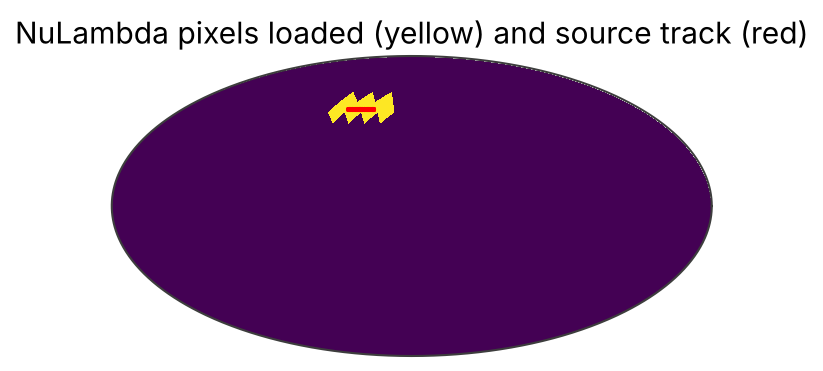

In [5]:
loaded = HealpixMap(base=lazy.axes['NuLambda'], data=lazy._loaded.astype(float))
plot, ax = loaded.plot(cbar=False)
ax.scatter(np.rad2deg(lon[::1000]), np.rad2deg(lat[::1000]), s=2, color='red',
           transform=ax.get_transform('world'))
ax.set_title('NuLambda pixels loaded (yellow) and source track (red)');

## Preloaded

In [6]:
del lazy

t0 = time.time()
preloaded = IRFRelativeHistUnpolarized.from_h5(irf_file, selections=selection, preload=True)
print(f'construction: {time.time() - t0:.1f} s, peak memory {peak_memory_GB():.2f} GB')

for i in range(2):
    t0 = time.time()
    prob_preloaded = np.asarray(preloaded.event_probability(photons, events))
    area_preloaded = np.asarray(preloaded.effective_area_cm2(photons))
    print(f'evaluation {i}: {time.time() - t0:.1f} s, peak memory {peak_memory_GB():.2f} GB')


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide




WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



...


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide


WARNING RuntimeWarning: invalid value encountered in divide



construction: 46.4 s, peak memory 10.00 GB


evaluation 0: 1.3 s, peak memory 10.09 GB


evaluation 1: 1.2 s, peak memory 10.13 GB


## Same results

In [7]:
print('max relative difference, event probability:',
      np.max(np.abs(prob_lazy - prob_preloaded) / np.maximum(np.abs(prob_preloaded), 1e-300)))
print('max relative difference, effective area:',
      np.max(np.abs(area_lazy - area_preloaded) / np.maximum(np.abs(area_preloaded), 1e-300)))
print('events with nonzero probability:', np.count_nonzero(prob_preloaded), 'of', n)

max relative difference, event probability: 0.0
max relative difference, effective area: 0.0
events with nonzero probability: 192948 of 200000


For reference, before this change `from_h5` read and normalized everything: 43 s and a
12.2 GB peak on this machine, with the same selection.

With `selections`, only the `Ei` bins that can produce a measured energy inside them are
read. The `Epsilon` axis of this file goes down to -1 (any `Ei` can deposit a small
energy), so for a 200 keV - 5 MeV cut all 15 `Ei` bins are needed:

In [8]:
print(preloaded.axes['Ei'].edges)

[   10.     100.     200.     252.73   319.37   403.59   510.     600.
   916.89  1401.13  2141.13  3271.95  5000.    7000.    9000.   10000.  ]
